# 05 — Attention Mechanism

## Terms & Definitions
- **Attention**: a mechanism that lets each position in a sequence look at (and pull information from) every other position, weighted by relevance.
- **Query (Q), Key (K), Value (V)**: three learned projections of each token's embedding. Intuitively — Query = "what am I looking for?", Key = "what do I contain?", Value = "what do I actually offer if you attend to me?"
- **Attention scores/weights**: how much each token attends to every other token — computed from Q·K similarity, then normalized with softmax.
- **Scaled dot-product attention**: the specific attention formula Transformers use (dot product of Q and K, scaled, softmaxed, then used to weight V).
- **Multi-head attention**: running several independent attention computations ("heads") in parallel, each potentially learning to focus on different kinds of relationships, then combining their outputs.
- **Causal mask**: a constraint that prevents a token from attending to future tokens — essential for autoregressive generation (a model predicting token 5 can't be allowed to peek at token 6).

## Why Attention? The Problem It Solves
Recall from notebook 01: RNNs/LSTMs process tokens one at a time, compressing everything seen so far into a fixed-size hidden state. Two problems:
1. **Information bottleneck**: cramming an entire long context into one fixed-size vector loses information, especially over long distances.
2. **Sequential computation**: token 100 can't be processed until tokens 1–99 have been, one at a time — slow, and hard to parallelize on GPUs.

**Attention's insight**: instead of compressing history into one hidden state, let every token directly look at every other token and decide (via learned weights) how much to borrow from each. This is computed for all positions *simultaneously* — highly parallelizable — and nothing gets "forgotten" due to distance the way it can in an RNN.

## History
Attention was introduced in 2014-2015 for neural machine translation (Bahdanau et al., Luong et al.) as an add-on to RNNs, letting a decoder "look back" at relevant encoder states instead of relying solely on a compressed context vector. **"Attention Is All You Need" (Vaswani et al., 2017)** made the radical move of removing the RNN entirely — showing that attention *alone*, stacked in blocks with feedforward layers (notebook 06), was sufficient and dramatically more parallelizable. That paper's architecture is the direct ancestor of GPT, BERT, and every major LLM since.

## The Math (light)

For queries $Q$, keys $K$, and values $V$ (each a matrix of shape `(seq_len, head_dim)`):

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

Step by step:
1. $QK^T$: dot product every query against every key → a `(seq_len, seq_len)` matrix of raw similarity scores.
2. Divide by $\sqrt{d_k}$ (where $d_k$ is the key dimension): keeps the scores from growing too large as dimensionality increases, which would otherwise push softmax into a regime with vanishing gradients.
3. `softmax` (row-wise): turn each row of raw scores into a probability distribution — "how much should this token attend to every other token?"
4. Multiply by $V$: use those probabilities to take a weighted average of every token's value vector.

**Causal masking** simply sets the score to $-\infty$ (before softmax) for any position $j > i$, so token $i$ can never attend to a future token $j$ — after softmax, $-\infty$ becomes probability 0.


In [1]:
import sys
sys.path.insert(0, "..")

import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)


## Attention From Scratch, on a Toy Sequence

Let's implement the formula literally, on a made-up sequence of 5 tokens with a small embedding dimension, so every step is easy to inspect.


In [2]:
seq_len, head_dim = 5, 4

# Pretend these are already the Q, K, V projections for a 5-token sequence.
Q = torch.randn(seq_len, head_dim)
K = torch.randn(seq_len, head_dim)
V = torch.randn(seq_len, head_dim)

# Step 1: raw similarity scores between every query and every key.
scores = Q @ K.T
print("raw scores shape:", scores.shape)  # (seq_len, seq_len) -- token i's row = its scores vs every token j
print(scores)


raw scores shape: torch.Size([5, 5])
tensor([[-0.9765,  0.6721, -2.3167,  1.5069,  1.2209],
        [ 0.6872, -0.0101, -3.3103, -1.9804,  1.7093],
        [ 1.2305, -0.8079,  0.6102, -0.8815,  0.3261],
        [ 1.0234, -0.5026,  4.2505, -1.1901, -3.0824],
        [ 1.8597, -1.5543,  3.4806, -1.1627, -0.6735]])


In [3]:
# Step 2: scale by sqrt(head_dim) to keep the softmax well-behaved.
scaled_scores = scores / math.sqrt(head_dim)
print(scaled_scores)


tensor([[-0.4883,  0.3361, -1.1583,  0.7534,  0.6104],
        [ 0.3436, -0.0050, -1.6552, -0.9902,  0.8546],
        [ 0.6153, -0.4039,  0.3051, -0.4408,  0.1630],
        [ 0.5117, -0.2513,  2.1252, -0.5950, -1.5412],
        [ 0.9299, -0.7772,  1.7403, -0.5813, -0.3368]])


## Causal Masking

Before softmax, we block attention to future positions by setting those scores to $-\infty$.


In [4]:
causal_mask = torch.tril(torch.ones(seq_len, seq_len))  # lower-triangular: 1s on/below diagonal
print("causal mask (1 = allowed to attend, 0 = blocked):")
print(causal_mask)


causal mask (1 = allowed to attend, 0 = blocked):
tensor([[1., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0.],
        [1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1.]])


In [5]:
masked_scores = scaled_scores.masked_fill(causal_mask == 0, float("-inf"))
print(masked_scores)


tensor([[-0.4883,    -inf,    -inf,    -inf,    -inf],
        [ 0.3436, -0.0050,    -inf,    -inf,    -inf],
        [ 0.6153, -0.4039,  0.3051,    -inf,    -inf],
        [ 0.5117, -0.2513,  2.1252, -0.5950,    -inf],
        [ 0.9299, -0.7772,  1.7403, -0.5813, -0.3368]])


In [6]:
# Step 3: softmax each row -- turns scores into a valid probability distribution per token.
attn_weights = F.softmax(masked_scores, dim=-1)
print("attention weights (rows sum to 1):")
print(attn_weights)
print()
print("row sums:", attn_weights.sum(dim=-1))


attention weights (rows sum to 1):
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5863, 0.4137, 0.0000, 0.0000, 0.0000],
        [0.4775, 0.1723, 0.3502, 0.0000, 0.0000],
        [0.1467, 0.0684, 0.7364, 0.0485, 0.0000],
        [0.2543, 0.0461, 0.5718, 0.0561, 0.0717]])

row sums: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


In [7]:
# Step 4: weighted sum of value vectors.
output = attn_weights @ V
print("attention output shape:", output.shape)
print(output)


attention output shape: torch.Size([5, 4])
tensor([[ 1.5091,  2.0820,  1.7067,  2.3804],
        [ 1.6880,  1.5481,  0.9922,  1.2147],
        [ 1.6315,  0.6543,  0.9321,  1.2434],
        [ 1.5485, -0.7053,  0.5075,  0.7235],
        [ 1.4116, -0.2794,  0.6599,  0.9397]])


Notice row 0 of `attn_weights` has weight 1.0 on column 0 and 0.0 everywhere else — token 0 has no earlier tokens to attend to besides itself, exactly as the causal mask intends. Row 4 (the last token) has nonzero weight spread across all 5 columns, since it's allowed to attend to everything up to and including itself.

## Visualizing an Attention Matrix

Attention weights are often visualized as a heatmap — rows are "the token doing the attending," columns are "the token being attended to." This is a very common diagnostic plot in LLM research.


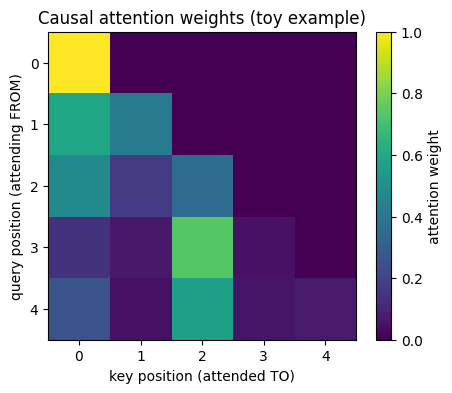

In [8]:
plt.figure(figsize=(5, 4))
plt.imshow(attn_weights.detach().numpy(), cmap="viridis")
plt.colorbar(label="attention weight")
plt.xlabel("key position (attended TO)")
plt.ylabel("query position (attending FROM)")
plt.title("Causal attention weights (toy example)")
plt.xticks(range(seq_len))
plt.yticks(range(seq_len))
plt.show()


The upper-right triangle is entirely dark (zero) — exactly the future positions the causal mask blocks.

## Multi-Head Attention

Instead of one attention computation over the full embedding dimension, split it into several smaller "heads" that run in parallel, each with its own learned Q/K/V projections. Concatenate their outputs at the end. Intuition: different heads can specialize — e.g. one head might learn to track "the subject of this sentence," another "the most recent noun," etc. — though in practice what each head learns emerges from training, not from explicit design.


In [9]:
import torch.nn as nn

class MultiHeadAttentionDemo(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head = n_head
        self.head_dim = n_embd // n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.out_proj = nn.Linear(n_embd, n_embd)

    def forward(self, x):
        B, T, C = x.shape
        qkv = self.qkv(x)
        q, k, v = qkv.split(C, dim=2)
        # Reshape (B, T, C) -> (B, n_head, T, head_dim) so each head attends independently.
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        causal_mask = torch.tril(torch.ones(T, T)).view(1, 1, T, T)
        scores = scores.masked_fill(causal_mask == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)

        out = weights @ v                                  # (B, n_head, T, head_dim)
        out = out.transpose(1, 2).contiguous().view(B, T, C)  # merge heads back together
        return self.out_proj(out), weights

mha = MultiHeadAttentionDemo(n_embd=16, n_head=4)
x = torch.randn(1, 6, 16)  # 1 sequence, 6 tokens, 16-dim embeddings
out, weights = mha(x)
print("input shape: ", x.shape)
print("output shape:", out.shape)
print("per-head attention weights shape:", weights.shape, "(batch, heads, query_pos, key_pos)")


input shape:  torch.Size([1, 6, 16])
output shape: torch.Size([1, 6, 16])
per-head attention weights shape: torch.Size([1, 4, 6, 6]) (batch, heads, query_pos, key_pos)


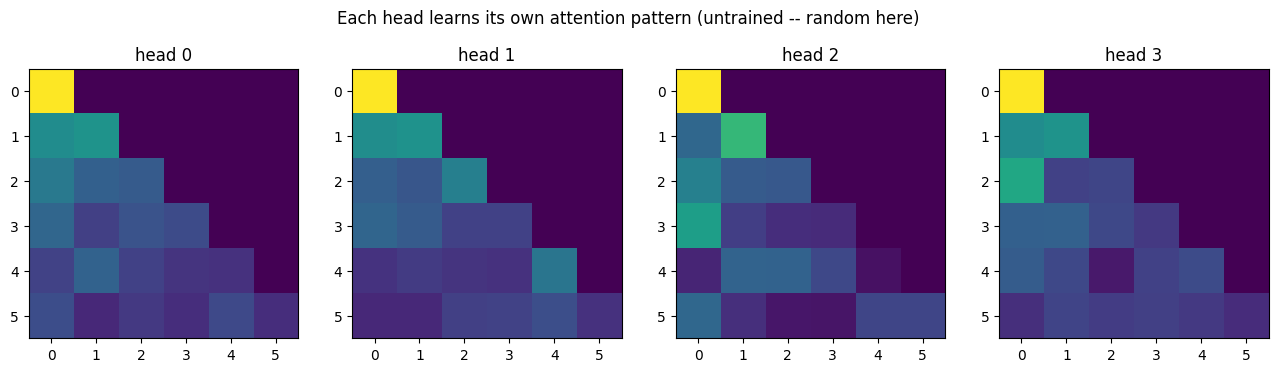

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for h in range(4):
    axes[h].imshow(weights[0, h].detach().numpy(), cmap="viridis")
    axes[h].set_title(f"head {h}")
plt.suptitle("Each head learns its own attention pattern (untrained -- random here)")
plt.show()


Since this multi-head module is freshly initialized (untrained), the four heads don't show any meaningful specialization yet — just four different random causal patterns. After real pretraining (notebook 08), heads in a trained model often show clear, interpretable-looking patterns (e.g. always attending to the previous token, or to the first token in the sequence).

## Exercise
`GPTMicro`'s actual attention implementation lives in `src/model.py: CausalSelfAttention` — open it and compare it line-by-line to `MultiHeadAttentionDemo` above. It's nearly identical; the production version just adds dropout for regularization and registers the causal mask as a buffer (so it isn't retrained, just reused).

## Summary
- Attention lets every token directly look at every other (allowed) token, weighted by learned relevance — no information bottleneck, fully parallelizable.
- The formula: scaled dot-product of Q and K, softmax to get weights, weighted sum of V.
- Causal masking blocks attention to future positions, which is what makes autoregressive (left-to-right) generation possible.
- Multi-head attention runs several attention computations in parallel and lets different heads specialize.

Next: **06 — Transformer Architecture** (assembling attention + the notebook-04 building blocks into a full decoder block, and stacking blocks into a real model).
